## 0. Setup

In [2]:
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.options.display.float_format = "{:,.2f}".format

API_URL = "http://localhost:8000"
RAW, CLEAN = Path("data/raw"), Path("data/clean")
RAW.mkdir(parents=True, exist_ok=True); CLEAN.mkdir(parents=True, exist_ok=True)

ENDPOINTS = {
    "retail_sales": "retail/sales",
    "ecom_sales":   "ecom/sales",
    "stores":       "stores",
    "articles":     "articles",
    "fx_rates":     "fx_rates",
}
print(requests.get(f"{API_URL}/health").json())

{'status': 'ok', 'records': {'retail_sales': 4456, 'ecom_sales': 3523, 'stores': 12, 'articles': 150, 'fx_rates': 3}}


## 1. Extract (complete pagination, raw saved untouched)

In [4]:
def fetch_all(endpoint, params=None, page_size=2000):
    params, rows, skip, total = dict(params or {}), [], 0, None
    while total is None or skip < total:
        r = requests.get(f"{API_URL}/{endpoint}",
                         params={**params, "limit": page_size, "skip": skip}, timeout=60)
        r.raise_for_status()
        js = r.json()
        total = js["total"]
        rows.extend(js["data"])
        if js["count"] == 0:
            break
        skip += js["count"]
    assert len(rows) == total, f"{endpoint}: got {len(rows)} of {total}"
    return pd.DataFrame(rows)

raw = {}
for name, ep in ENDPOINTS.items():
    raw[name] = fetch_all(ep)
    to_save = raw[name].copy()
    obj_cols = to_save.select_dtypes(include="object").columns
    to_save[obj_cols] = to_save[obj_cols].astype("string")
    to_save.to_parquet(RAW / f"{name}.parquet", index=False)
    print(f"{name:14s} {len(raw[name]):>8,} rows")

retail_sales      4,456 rows
ecom_sales        3,523 rows
stores               12 rows
articles            150 rows
fx_rates              3 rows


## 2. Profile (what does one row represent?)

In [5]:
def profile(df, name="", cats=(), keys=None):
    print(f"=== {name} === shape={df.shape}")
    print(pd.concat([df.dtypes.rename("dtype"), df.isna().sum().rename("nulls"),
                     df.nunique().rename("unique")], axis=1).to_string())
    print("full-row duplicates:", df.duplicated().sum())
    if keys:
        print("duplicates on business key", keys, ":", df.duplicated(keys).sum())
    for c in cats:
        print(f"\n{c}:\n{df[c].value_counts(dropna=False).head(12).to_string()}")
    return df.head(3)

profile(raw["retail_sales"], "retail", cats=["transaction_type", "reversal_indicator", "country", "currency"],
        keys=["transaction_number", "line_number"])

=== retail === shape=(4456, 16)
                        dtype  nulls  unique
transaction_number     object      0    3372
line_number             int64      0       6
transaction_type       object      0       2
reversal_indicator     object   4385       1
original_tran_number   object   4240     199
calendar_date          object      0     346
country                object      0       3
store_spot             object      0      12
group_article          object      0     150
size_page              object      0      12
sold_qty               object      0       5
return_qty            float64   4311       3
return_value          float64   4311     114
net_qty                 int64      0       6
net_sales              object      0    1056
currency               object      0       3
full-row duplicates: 0
duplicates on business key ['transaction_number', 'line_number'] : 0

transaction_type:
transaction_type
SALE      4311
RETURN     145

reversal_indicator:
reversal_indicator
None 

,transaction_number,line_number,transaction_type,reversal_indicator,original_tran_number,calendar_date,country,store_spot,group_article,size_page,sold_qty,return_qty,return_value,net_qty,net_sales,currency
0,1054250101001462,1,SALE,None,None,2025-01-01,AR,061054,YZ3099,XS,1,NaN,NaN,1,"35,200.00",ARS
1,1054250101001462,2,SALE,None,None,2025-01-01,AR,061054,KT5452,10,1,NaN,NaN,1,"120,800.00",ARS
2,1054250101001462,3,SALE,None,None,2025-01-01,AR,061054,RJ5204,NS,2,NaN,NaN,2,"42,000.00",ARS


In [6]:
profile(raw["ecom_sales"], "ecom", cats=["transaction_type", "reversal_indicator", "fulfillment_channel",
                                         "order_origin", "country", "currency"],
        keys=["ecom_reference_number", "sor_itm"])

=== ecom === shape=(3523, 19)
                         dtype  nulls  unique
ecom_reference_number   object      0    2431
sor_itm                  int64      0       7
transaction_type        object      0       2
reversal_indicator      object   3508       1
original_tran_number    object   3209     292
consumer_order_date     object      0     186
calendar_date           object      0     180
country                 object      0       3
order_origin            object      0       2
fulfillment_channel     object      0       2
store_spot              object   3103       6
group_article           object      0     150
size_page               object      0      12
sold_qty                 int64      0       4
return_qty             float64   3224       3
return_value           float64   3224     221
net_qty                  int64      0       6
net_sales              float64      0    1079
currency                object      0       3
full-row duplicates: 0
duplicates on business key 

,ecom_reference_number,sor_itm,transaction_type,reversal_indicator,original_tran_number,consumer_order_date,calendar_date,country,order_origin,fulfillment_channel,store_spot,group_article,size_page,sold_qty,return_qty,return_value,net_qty,net_sales,currency
0,AR100002274,10,SALE,None,None,2024-12-31,2025-01-01,AR,WEB,DC,None,KR3604,11,1,NaN,NaN,1,"127,000.00",ARS
1,AR100002274,20,SALE,None,None,2024-12-30,2025-01-01,AR,WEB,DC,None,ZT9277,10,1,NaN,NaN,1,"83,300.00",ARS
2,AR100002274,30,SALE,None,None,2024-12-31,2025-01-01,AR,WEB,DC,None,MP2860,9,1,NaN,NaN,1,"105,000.00",ARS


In [7]:
for n in ["stores", "articles", "fx_rates"]:
    display(profile(raw[n], n))

=== stores === shape=(12, 5)
               dtype  nulls  unique
store_spot    object      0      12
store_name    object      0      12
country       object      0       3
city          object      0       7
store_format  object      0       3
full-row duplicates: 0


,store_spot,store_name,country,city,store_format
0,064129,Adi2 Store Andino,CO,Medellin,STORE
1,036709,Adi2 Outlet Oviedo,CO,Bogota,OUTLET
2,043197,Adi2 Store Unicentro,CO,Medellin,STORE


=== articles === shape=(150, 4)
                   dtype  nulls  unique
group_article     object      0     150
article_name      object      0     150
product_division  object      0       3
key_category      object      0       5
full-row duplicates: 0


,group_article,article_name,product_division,key_category
0,EX7699,Football Tee 7699,APPAREL,FOOTBALL
1,AJ4228,Football Trail Shoe 4228,FOOTWEAR,FOOTBALL
2,HE3449,Running Pant 3449,APPAREL,RUNNING


=== fx_rates === shape=(3, 3)
                 dtype  nulls  unique
country         object      0       3
currency        object      0       3
units_per_eur  float64      0       3
full-row duplicates: 0


,country,currency,units_per_eur
0,CO,COP,"4,500.00"
1,MX,MXN,20.00
2,AR,ARS,"1,000.00"


In [8]:
def num(df, cols=("sold_qty", "return_qty", "return_value", "net_qty", "net_sales")):
    d = df.copy()
    for c in cols:
        d[c] = pd.to_numeric(d[c], errors="coerce")
    return d

r = num(raw["retail_sales"]); e = num(raw["ecom_sales"])
r["date"] = pd.to_datetime(r["calendar_date"], errors="coerce")
e["date"] = pd.to_datetime(e["calendar_date"], errors="coerce")
e["order_date"] = pd.to_datetime(e["consumer_order_date"], errors="coerce")
print("fechas no parseadas:", r["date"].isna().sum(), e["date"].isna().sum(), e["order_date"].isna().sum())

fechas no parseadas: 394 0 0


## 3. Clean each source (one function per source, returns a DataFrame, no globals)

In [10]:
def clean_stores(df):
    df = df.copy()
    df["store_spot"] = df["store_spot"].astype(str).str.strip().str.zfill(6)
    return df.drop_duplicates("store_spot")

def clean_articles(df):
    df = df.copy()
    df["group_article"] = df["group_article"].astype(str).str.strip().str.upper()
    return df.drop_duplicates("group_article")

def clean_fx(df):
    df = df.copy()
    assert df["units_per_eur"].gt(0).all()
    return df 

stores, articles, fx = clean_stores(raw["stores"]), clean_articles(raw["articles"]), clean_fx(raw["fx_rates"])
fx

,country,currency,units_per_eur
0,CO,COP,"4,500.00"
1,MX,MXN,20.00
2,AR,ARS,"1,000.00"


In [11]:
COMMON_COLS = ["source", "order_id", "line_id", "transaction_type", "reversal_indicator", "original_tran_number",
               "date", "country", "store_spot", "group_article", "size_page",
               "sold_qty", "return_qty", "return_value", "net_qty", "net_sales", "currency",
               "fulfillment_channel", "order_origin"]

def _common_cleaning(df):
    df = df.copy()
    df["date"] = pd.to_datetime(df["calendar_date"], errors="coerce")
    df["group_article"] = df["group_article"].astype(str).str.strip().str.upper()
    df["country"] = df["country"].astype(str).str.strip().str.upper()
    for c in ["sold_qty", "return_qty", "return_value", "net_qty", "net_sales"]:
        df[c] = pd.to_numeric(df[c], errors="coerce").fillna(0)
    return df

def clean_retail(df):
    df = _common_cleaning(df)
    df["source"] = "retail"
    df["order_id"], df["line_id"] = df["transaction_number"].astype(str), df["line_number"]
    df["store_spot"] = df["store_spot"].astype(str).str.strip().str.zfill(6)
    df["fulfillment_channel"] = pd.NA; df["order_origin"] = pd.NA
    df = df.drop_duplicates(subset=["transaction_number", "line_number"], keep="first")
    return df[COMMON_COLS]

def clean_ecom(df):
    df = _common_cleaning(df)
    df["source"] = "ecom"
    df["order_id"], df["line_id"] = df["ecom_reference_number"].astype(str), df["sor_itm"]
    df["store_spot"] = df["store_spot"].astype("string").str.strip().str.zfill(6)
    df.loc[df["store_spot"].isin(["<NA>", "000NAN", "0000NA"]), "store_spot"] = pd.NA  # TODO: check real null patterns
    df = df.drop_duplicates(subset=["ecom_reference_number", "sor_itm"], keep="first")
    df["date"] = pd.to_datetime(df["calendar_date"], errors="coerce")
    return df[COMMON_COLS]

retail, ecom = clean_retail(raw["retail_sales"]), clean_ecom(raw["ecom_sales"])
for n, d in {"stores": stores, "articles": articles, "fx": fx, "retail": retail, "ecom": ecom}.items():
    d.to_parquet(CLEAN / f"{n}.parquet", index=False)

## 4. Business rules (void, channel, FX), with a reconciliation log at every step

In [12]:
recon = []
def log_step(step, df, to_eur=True):
    d = df.copy()
    d = d.merge(fx[["country", "units_per_eur"]], on="country", how="left")
    d["net_eur"] = d["net_sales"] / d["units_per_eur"]
    g = d.groupby("source").agg(rows=("net_sales", "size"), net_qty=("net_qty", "sum"), net_eur=("net_eur", "sum"))
    g.insert(0, "step", step)
    recon.append(g.reset_index())

sales = pd.concat([retail, ecom], ignore_index=True)
log_step("0. clean sources", sales)

In [13]:
def drop_voids(df):
    is_x = df["reversal_indicator"] == "X"
    originals = df.loc[is_x, ["source", "original_tran_number"]].drop_duplicates()
    originals = originals.rename(columns={"original_tran_number": "order_id"})
    originals["es_original"] = True

    df = df.merge(originals, on=["source", "order_id"], how="left")
    es_original = df["es_original"].fillna(False).astype(bool)

    print(f"anulaciones (X): {is_x.sum()} | originales cancelados: {(es_original & ~is_x).sum()}")
    return df[~(is_x | es_original)].drop(columns="es_original")

sales = drop_voids(sales)
log_step("1. excluded voids (reversal + original)", sales)

anulaciones (X): 86 | originales cancelados: 86


C:\Users\USUARIO\AppData\Local\Temp\ipykernel_1028\642565626.py:8: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  es_original = df["es_original"].fillna(False).astype(bool)


In [15]:
def assign_channel(df):
    df = df.copy()
    is_store_order = (df["source"] == "ecom") & (df["fulfillment_channel"] == "STORE")
    df["fulfilled_by_store_flag"] = is_store_order
    df["channel"] = np.where(df["source"] == "retail", "RETAIL", np.where(is_store_order, "RETAIL", "ECOM"))
    df.loc[(df["source"] == "ecom") & ~is_store_order, "store_spot"] = pd.NA

    retail_ids = set(df.loc[df["source"] == "retail", "order_id"])
    ecom_store_ids = set(df.loc[is_store_order, "order_id"])
    print("pedidos STORE de ECOM que también están en Retail:", len(retail_ids & ecom_store_ids))

    return df

sales = assign_channel(sales)
log_step("2. channel assignment (ship-from-store -> RETAIL)", sales)
pd.crosstab([sales["source"], sales["fulfillment_channel"].fillna("n/a")], sales["channel"])

pedidos STORE de ECOM que también están en Retail: 0


channel                     ECOM  RETAIL
source fulfillment_channel              
ecom   DC                   3075       0
       STORE                   0     418
retail n/a                     0    4314

## 5. Final table `fact_sellout_performance`

In [16]:
def checked_merge(left, right, on, name=""):
    n0, s0 = len(left), left["net_sales"].sum()
    out = left.merge(right, on=on, how="left", validate="m:1")
    assert len(out) == n0, f"{name}: filas {n0} -> {len(out)}"
    assert np.isclose(out["net_sales"].sum(), s0), f"{name}: las ventas cambiaron"
    print(f"{name}: {n0:,} filas OK")
    return out

def build_fact(df, stores, articles, fx):
    fx_ = fx[["country", "currency", "units_per_eur"]].rename(columns={"currency": "fx_currency"})
    d = checked_merge(df, fx_, "country", "fx")
    assert d["units_per_eur"].notna().all(), "hay países sin tasa"
    print("filas con moneda distinta a la del país:", (d["currency"] != d["fx_currency"]).sum())

    def eur(x): return (x["net_sales"] / x["units_per_eur"]).sum()

    d = checked_merge(d, articles[["group_article", "product_division", "key_category"]], "group_article", "articles")
    sin_art = d["product_division"].isna()
    print(f"artículos sin maestro: {sin_art.sum()} filas | {eur(d[sin_art]):,.0f} EUR")
    d[["product_division", "key_category"]] = d[["product_division", "key_category"]].fillna("UNKNOWN")

    d = checked_merge(d, stores[["store_spot", "store_name"]], "store_spot", "stores")
    sin_tienda = d["store_spot"].notna() & d["store_name"].isna()
    print(f"tiendas sin maestro: {sin_tienda.sum()} filas | {eur(d[sin_tienda]):,.0f} EUR")
    d.loc[sin_tienda, "store_name"] = "UNKNOWN"      # sin store_spot (DC) queda vacío, como pide el contrato

    print("filas sin fecha válida:", d["date"].isna().sum())
    d["month"] = d["date"].dt.strftime("%Y-%m")

  
    d["gross_qty"] = d["net_qty"] + d["return_qty"]
    d["gross_sales_local"] = d["net_sales"] + d["return_value"]
    d["return_sales_local"] = d["return_value"]

    d["gross_sales_eur"] = d["gross_sales_local"] / d["units_per_eur"]
    d["return_sales_eur"] = d["return_sales_local"] / d["units_per_eur"]
    d["net_sales_eur"] = d["gross_sales_eur"] - d["return_sales_eur"]

    grain = ["month", "country", "channel", "store_spot", "store_name", "group_article",
             "product_division", "key_category", "fulfilled_by_store_flag"]
    out = (d.groupby(grain, dropna=False, as_index=False)
             .agg(gross_qty=("gross_qty", "sum"), return_qty=("return_qty", "sum"),
                  gross_sales_eur=("gross_sales_eur", "sum"), return_sales_eur=("return_sales_eur", "sum"),
                  net_sales_eur=("net_sales_eur", "sum")))
    out["net_qty"] = out["gross_qty"] - out["return_qty"]

  
    assert np.isclose(out["net_sales_eur"].sum(), eur(d)), "la agregación perdió o duplicó ventas"
    assert np.isclose(out["net_qty"].sum(), d["net_qty"].sum()), "net_qty no cuadra con la fuente"
    key = ["month", "country", "channel", "store_spot", "group_article", "fulfilled_by_store_flag"]
    assert not out.duplicated(key).any(), "llaves duplicadas en el grano"
    print("fact:", out.shape, "| net EUR:", f"{out['net_sales_eur'].sum():,.0f}")
    return out

fact = build_fact(sales, stores, articles, fx)
fact.to_parquet("fact_sellout_performance.parquet", index=False)

fx: 7,807 filas OK
filas con moneda distinta a la del país: 0
articles: 7,807 filas OK
artículos sin maestro: 0 filas | 0 EUR
stores: 7,807 filas OK
tiendas sin maestro: 0 filas | 0 EUR
filas sin fecha válida: 384
fact: (5424, 15) | net EUR: 664,837


## 6. Validation and reconciliation

In [17]:
recon_df = pd.concat(recon, ignore_index=True)
log_final = (fact.assign(source=np.where(fact["fulfilled_by_store_flag"], "ecom", fact["channel"].str.lower()))
                 .groupby("source").agg(rows=("net_sales_eur", "size"), net_qty=("net_qty", "sum"),
                                        net_eur=("net_sales_eur", "sum")).reset_index())
log_final.insert(0, "step", "9. fact_sellout_performance (aggregated)")
display(pd.concat([recon_df, log_final]).sort_values(["source", "step"]))

grain = ["month", "country", "channel", "store_spot", "group_article", "fulfilled_by_store_flag"]
assert not fact.duplicated(grain).any(), "duplicate keys at grain"
assert fact["net_sales_eur"].notna().all()
# TODO: net = gross - returns check; every row difference in the table above explained in NOTES.md

,source,step,rows,net_qty,net_eur
0,ecom,0. clean sources,3523,"3,628.00","282,707.30"
2,ecom,1. excluded voids (reversal + original),3493,"3,596.00","280,855.90"
4,ecom,2. channel assignment (ship-from-store -> RETAIL),3493,"3,596.00","280,855.90"
0,ecom,9. fact_sellout_performance (aggregated),2128,"3,596.00","280,855.90"
1,retail,0. clean sources,4456,"5,140.00","395,811.40"
3,retail,1. excluded voids (reversal + original),4314,"4,978.00","383,980.80"
5,retail,2. channel assignment (ship-from-store -> RETAIL),4314,"4,978.00","383,980.80"
1,retail,9. fact_sellout_performance (aggregated),3296,"4,978.00","383,980.80"


## 7. Business question (only from `fact`)
**Q1 2026 vs Q1 2025, EUR.** (1) Is the data consistent with "growth is coming from online, stores are losing relevance"? (2) Which stores drive Retail and why?

In [18]:
f = pd.read_parquet("fact_sellout_performance.parquet")
f["year"] = f["month"].str[:4]
q1 = f[f["month"].str[5:7].isin(["01", "02", "03"]) & f["year"].isin(["2025", "2026"])]

def growth(df, by):
    t = df.pivot_table(index=by, columns="year", values="net_sales_eur", aggfunc="sum", fill_value=0)
    t["delta_eur"] = t["2026"] - t["2025"]
    t["growth_%"] = np.where(t["2025"] != 0, t["delta_eur"] / t["2025"] * 100, np.nan)
    return t

display(growth(q1, ["channel"]))
display(growth(q1, ["country", "channel"]))
# Key comparison: "naive" view (ECOM source as-is) vs business-rule view (ship-from-store -> RETAIL)
display(growth(q1.assign(view=np.where(q1["fulfilled_by_store_flag"], "ECOM (ship-from-store)", q1["channel"])), ["view"]))

year,2025,2026,delta_eur,growth_%
channel,,,,
ECOM,"115,876.00","131,993.40","16,117.40",13.91
RETAIL,"186,359.40","198,911.90","12,552.50",6.74


year                  2025       2026  delta_eur  growth_%
country channel                                           
AR      ECOM     29,061.20  33,693.50   4,632.30     15.94
        RETAIL   41,588.80  42,417.70     828.90      1.99
CO      ECOM     33,180.10  39,712.00   6,531.90     19.69
        RETAIL   43,834.40  52,627.70   8,793.30     20.06
MX      ECOM     53,634.70  58,587.90   4,953.20      9.24
        RETAIL  100,936.20 103,866.50   2,930.30      2.90

year,2025,2026,delta_eur,growth_%
view,,,,
ECOM,"115,876.00","131,993.40","16,117.40",13.91
ECOM (ship-from-store),"3,047.80","29,938.70","26,890.90",882.31
RETAIL,"183,311.60","168,973.20","-14,338.40",-7.82


In [ ]:
# Q2: stores driving Retail. TODO: like-for-like (stores active in both periods) vs new stores,
#     ship-from-store share per store, store_format (needs stores master), concentration (top 10 share)
retail_q1 = q1[q1["channel"] == "RETAIL"]
stores_g = growth(retail_q1, ["store_spot", "store_name"]).sort_values("delta_eur")
display(stores_g.head(10)); display(stores_g.tail(10))

,year,2025,2026,delta_eur,growth_%
store_spot,store_name,,,,
099404,Adi2 Brand Center Andares,"20,872.00","17,804.60","-3,067.40",-14.70
036709,Adi2 Outlet Oviedo,"16,519.20","14,086.30","-2,432.90",-14.73
075701,Adi2 Store Perisur,"23,572.70","21,168.30","-2,404.40",-10.20
068517,Adi2 Store Unicenter,"16,695.60","14,859.20","-1,836.40",-11.00
061054,Adi2 Brand Center Solar,"11,010.40","9,693.50","-1,316.90",-11.96
074962,Adi2 Outlet Toreo,"21,977.70","22,486.20",508.50,2.31
038303,Adi2 Brand Center Titan,"15,394.80","16,626.80","1,232.00",8.00
015806,Adi2 Outlet Antara,"15,399.20","19,315.00","3,915.80",25.43
041956,Adi2 Store Galerias,"19,114.60","23,092.40","3,977.80",20.81


,year,2025,2026,delta_eur,growth_%
store_spot,store_name,,,,
036709,Adi2 Outlet Oviedo,"16,519.20","14,086.30","-2,432.90",-14.73
075701,Adi2 Store Perisur,"23,572.70","21,168.30","-2,404.40",-10.20
068517,Adi2 Store Unicenter,"16,695.60","14,859.20","-1,836.40",-11.00
061054,Adi2 Brand Center Solar,"11,010.40","9,693.50","-1,316.90",-11.96
074962,Adi2 Outlet Toreo,"21,977.70","22,486.20",508.50,2.31
038303,Adi2 Brand Center Titan,"15,394.80","16,626.80","1,232.00",8.00
015806,Adi2 Outlet Antara,"15,399.20","19,315.00","3,915.80",25.43
041956,Adi2 Store Galerias,"19,114.60","23,092.40","3,977.80",20.81
012209,Adi2 Store Alto Palermo,"13,882.80","17,865.00","3,982.20",28.68


In [21]:
ret = q1[q1["channel"] == "RETAIL"].copy()
ret["tipo"] = np.where(ret["fulfilled_by_store_flag"], "ship_from_store", "tienda_fisica")
x = ret.pivot_table(index="store_name", columns=["year", "tipo"], values="net_sales_eur",
                    aggfunc="sum", fill_value=0)
display(x.round(0))

year                                 2025                          2026              
tipo                      ship_from_store tienda_fisica ship_from_store tienda_fisica
store_name                                                                           
Adi2 Brand Center Andares            0.00     20,872.00            0.00     17,805.00
Adi2 Brand Center Solar              0.00     11,010.00            0.00      9,694.00
Adi2 Brand Center Titan              0.00     15,395.00        1,662.00     14,964.00
Adi2 Outlet Antara                   0.00     15,399.00        5,732.00     13,583.00
Adi2 Outlet Oviedo                   0.00     16,519.00            0.00     14,086.00
Adi2 Outlet Toreo                3,048.00     18,930.00        4,944.00     17,542.00
Adi2 Store Alto Palermo              0.00     13,883.00        5,771.00     12,094.00
Adi2 Store Galerias                  0.00     19,115.00        4,946.00     18,146.00
Adi2 Store Perisur                   0.00     23,573.00            0.00     21,168.00
Adi2 Store Unicenter                 0.00     16,696.00            0.00     14,859.00
Adi2 Store Unicentro                 0.00     11,920.00        6,882.00     15,032.00

## 8. Charts for leadership

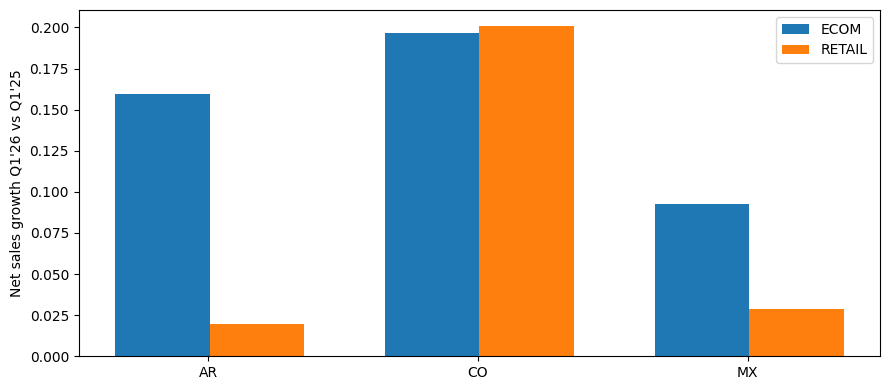

In [20]:
ch = growth(q1, ["country", "channel"])[["2025", "2026"]].reset_index()
fig, ax = plt.subplots(figsize=(9, 4))
# TODO: clear title = the message (not the topic), labels in EUR M, one chart per message
for i, (k, g) in enumerate(ch.groupby("channel")):
    ax.bar(np.arange(len(g)) + i * 0.35, g["2026"] / g["2025"] - 1, width=0.35, label=k)
ax.set_xticks(np.arange(len(g)) + 0.17); ax.set_xticklabels(g["country"])
ax.axhline(0, color="k", lw=.5); ax.legend(); ax.set_ylabel("Net sales growth Q1'26 vs Q1'25")
plt.tight_layout(); plt.savefig("chart_growth.png", dpi=150)

## 9. Insights (what I observe -> what it means -> what I would do)
1. Las tiendas no pierden relevancia, son el motor del crecimiento online
2. El crecimiento de Retail depende de Colombia, y México y Argentina están casi estancados
3. El ship-from-store crece por expansión del servicio y se frenará al completarse el despliegue.

